<a href="https://colab.research.google.com/github/ANKITHATALAPALLY/ANKITHA-T_4NI23CI017_MLLAB_E1/blob/main/MLLAB6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score

# Create dataset
data = {
    'Hours_Studied': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Passed_Exam': [0, 0, 0, 0, 1, 0, 1, 1, 1, 1]
}

df = pd.DataFrame(data)

# Separate features and target
X = df[['Hours_Studied']]
y = df['Passed_Exam']

# Split into training and testing data
X_train, X_test = X.iloc[:8], X.iloc[8:]
y_train, y_test = y.iloc[:8], y.iloc[8:]

# Define models
models = {
    "Single Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging (Random Forest)": RandomForestClassifier(
        n_estimators=10, random_state=42
    ),
    "Boosting (AdaBoost)": AdaBoostClassifier(
        n_estimators=10, random_state=42
    )
}

# Train and evaluate models
print("--- Accuracy Results ---")

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    print(f"{name}: {accuracy * 100:.0f}%")

--- Accuracy Results ---
Single Decision Tree: 100%
Bagging (Random Forest): 100%
Boosting (AdaBoost): 100%


Dataset Shape: (569, 30)

Target Distribution:
1    62.74%
0    37.26%
Name: proportion, dtype: object

--- Performance Report ---
                       Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Boosting (Gradient Boosting)    0.9561     0.9467  0.9861    0.9660   0.9907
         Boosting (AdaBoost)    0.9561     0.9467  0.9861    0.9660   0.9818
     Bagging (Random Forest)    0.9561     0.9589  0.9722    0.9655   0.9937
           Bagging (Generic)    0.9386     0.9452  0.9583    0.9517   0.9927
        Single Decision Tree    0.9123     0.9559  0.9028    0.9286   0.9157


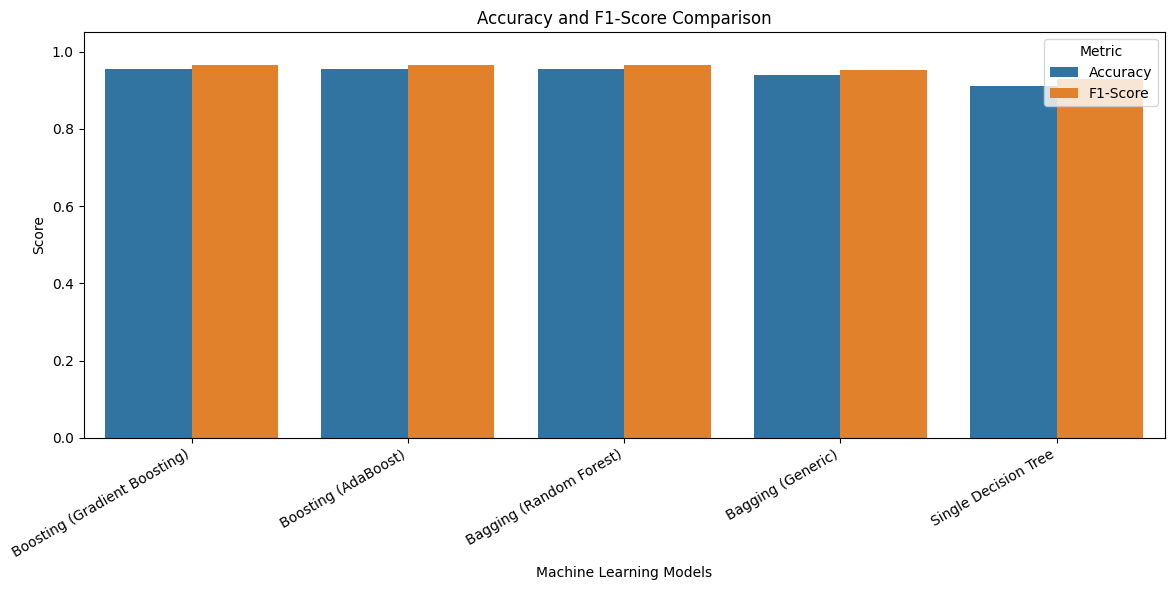

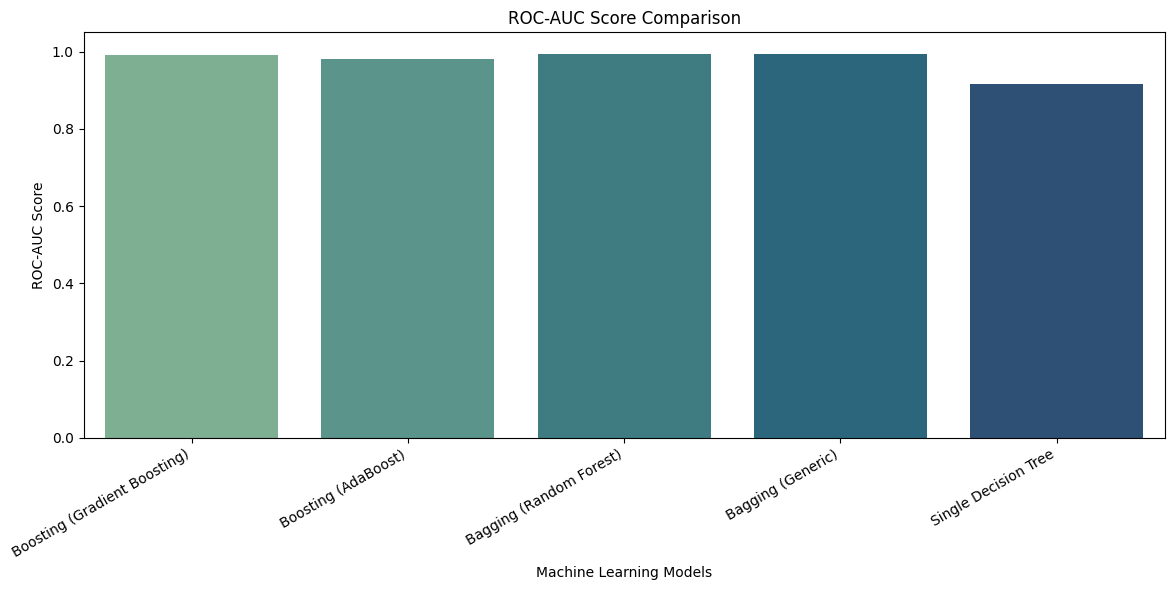

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

# Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Display dataset information
print("Dataset Shape:", X.shape)

print("\nTarget Distribution:")
print(y.value_counts(normalize=True).map('{:.2%}'.format))

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define models
models = {
    "Single Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Bagging (Generic)": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42
    ),

    "Bagging (Random Forest)": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Boosting (AdaBoost)": AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Boosting (Gradient Boosting)": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Store evaluation results
metrics_data = []

# Train and evaluate each model
for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Predict probabilities
    y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    acc = accuracy_score(y_test, y_pred)

    prec = precision_score(y_test, y_pred, zero_division=0)

    rec = recall_score(y_test, y_pred, zero_division=0)

    f1 = f1_score(y_test, y_pred, zero_division=0)

    roc_auc = roc_auc_score(y_test, y_proba)

    # Store results
    metrics_data.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# Convert results into DataFrame
results_df = pd.DataFrame(metrics_data)

# Sort models based on F1-score
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
)

# Display performance report
print("\n--- Performance Report ---")

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Visualization 1: Accuracy and F1-score comparison
plt.figure(figsize=(12, 6))

results_melted = pd.melt(
    results_df,
    id_vars=["Model"],
    value_vars=["Accuracy", "F1-Score"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Accuracy and F1-Score Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

# Visualization 2: ROC-AUC comparison
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC",
    hue="Model",
    palette="crest",
    legend=False
)

plt.title("ROC-AUC Score Comparison")
plt.ylabel("ROC-AUC Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()